# JobShield
## 04 — Deep Neural Network Training

### Objectives
1. Load the existing numerical feature matrices.
2. Build a feed-forward Deep Neural Network.
3. Handle class imbalance using class weights.
4. Train with validation monitoring.
5. Generate actual training curves.
6. Evaluate validation performance.
7. Save and verify the trained model.

The test dataset will not be used in this phase.

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import sparse
from IPython.display import display

from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

tf.keras.utils.set_random_seed(42)


def find_project_root():
    current = Path.cwd()

    for folder in [current] + list(current.parents):
        file = folder / "data" / "processed" / "train_features.npz"

        if file.is_file():
            return folder

    raise FileNotFoundError(
        "Run Phase 3 before training the DNN."
    )


PROJECT_ROOT = find_project_root()

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

MODEL_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Load saved feature matrices
X_train_sparse = sparse.load_npz(
    DATA_DIR / "train_features.npz"
)

X_val_sparse = sparse.load_npz(
    DATA_DIR / "validation_features.npz"
)

# Keras Dense layers will use float32 arrays
X_train = X_train_sparse.toarray().astype(np.float32)
X_val = X_val_sparse.toarray().astype(np.float32)

# Load target labels
train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")

y_train = train_df["fraudulent"].to_numpy(dtype=np.float32)
y_val = val_df["fraudulent"].to_numpy(dtype=np.float32)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert X_train.shape[1] == X_val.shape[1]

print("TensorFlow version:", tf.__version__)
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Input features:", X_train.shape[1])

print("\nData loaded successfully.")

c:\Users\Divyabhanu Rana\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
c:\Users\Divyabhanu Rana\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
c:\Users\Divyabhanu Rana\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.3

TensorFlow version: 2.20.0
Training shape: (12319, 3868)
Validation shape: (2640, 3868)
Input features: 3868

Data loaded successfully.


## 1. DNN Architecture

A feed-forward Deep Neural Network is used for binary
classification.

Architecture:

- Input layer: 3,868 features
- First hidden layer: 128 neurons, ReLU
- Dropout: 30%
- Second hidden layer: 64 neurons, ReLU
- Dropout: 20%
- Output layer: 1 neuron, Sigmoid

Binary cross-entropy measures classification loss.

Adam is used for optimisation.

Dropout and L2 regularisation help reduce overfitting.

In [2]:
tf.keras.backend.clear_session()

model = tf.keras.Sequential([
    tf.keras.layers.Input(
        shape=(X_train.shape[1],)
    ),

    tf.keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(0.0001)
    ),

    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(0.0001)
    ),

    tf.keras.layers.Dropout(0.20),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),
        tf.keras.metrics.Precision(
            name="precision"
        ),
        tf.keras.metrics.Recall(
            name="recall"
        ),
        tf.keras.metrics.AUC(
            name="pr_auc",
            curve="PR"
        )
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       495,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 503,553 (1.92 MB)

 Trainable params: 503,553 (1.92 MB)

 Non-trainable params: 0 (0.00 B)

## 2. Class Imbalance Handling

Fraudulent postings form a small percentage of the
training dataset.

Class weights will be calculated from training labels.

The minority class receives a higher weight so that
its classification errors contribute more heavily
to model training.

Early stopping will monitor validation performance
to help avoid unnecessary training and overfitting.

In [3]:
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.astype(int)
)

class_weight = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Calculated class weights:")
print(class_weight)

Calculated class weights:
{0: 0.5255994538783173, 1: 10.265833333333333}


In [4]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=0.00001
    )
]

print("Starting DNN training...")

history = model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=20,
    batch_size=128,

    class_weight=class_weight,
    callbacks=callbacks,

    verbose=2
)

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    REPORT_DIR / "dnn_training_history.csv",
    index=False
)

print("\nTraining completed.")
print("Epochs executed:", len(history_df))

display(history_df.tail())

Starting DNN training...
Epoch 1/20
97/97 - 3s - 28ms/step - accuracy: 0.9108 - loss: 0.4053 - pr_auc: 0.5263 - precision: 0.3150 - recall: 0.7083 - val_accuracy: 0.9409 - val_loss: 0.1696 - val_pr_auc: 0.8745 - val_precision: 0.4474 - val_recall: 0.9297 - learning_rate: 0.0010
Epoch 2/20
97/97 - 1s - 10ms/step - accuracy: 0.9581 - loss: 0.1359 - pr_auc: 0.9166 - precision: 0.5387 - recall: 0.9750 - val_accuracy: 0.9674 - val_loss: 0.1224 - val_pr_auc: 0.9181 - val_precision: 0.6050 - val_recall: 0.9453 - learning_rate: 0.0010
Epoch 3/20
97/97 - 1s - 10ms/step - accuracy: 0.9825 - loss: 0.0843 - pr_auc: 0.9683 - precision: 0.7376 - recall: 0.9933 - val_accuracy: 0.9758 - val_loss: 0.1043 - val_pr_auc: 0.9427 - val_precision: 0.6798 - val_recall: 0.9453 - learning_rate: 0.0010
Epoch 4/20
97/97 - 1s - 9ms/step - accuracy: 0.9904 - loss: 0.0638 - pr_auc: 0.9852 - precision: 0.8366 - recall: 0.9983 - val_accuracy: 0.9769 - val_loss: 0.0900 - val_pr_auc: 0.9528 - val_precision: 0.6914 - val

,accuracy,loss,pr_auc,precision,recall,val_accuracy,val_loss,val_pr_auc,val_precision,val_recall,learning_rate
3,0.990421,0.063782,0.985182,0.836592,0.998333,0.976894,0.090004,0.952787,0.691429,0.945312,0.001
4,0.994155,0.052344,0.994729,0.892857,1.000000,0.982955,0.078784,0.951133,0.764331,0.937500,0.001
5,0.997889,0.042280,0.995171,0.958466,1.000000,0.982955,0.077204,0.948188,0.761006,0.945312,0.001
6,0.997889,0.039444,0.997600,0.959936,0.998333,0.982576,0.069609,0.950101,0.780822,0.890625,0.001
7,0.998620,0.035712,0.999736,0.972447,1.000000,0.983333,0.069353,0.943673,0.783784,0.906250,0.001


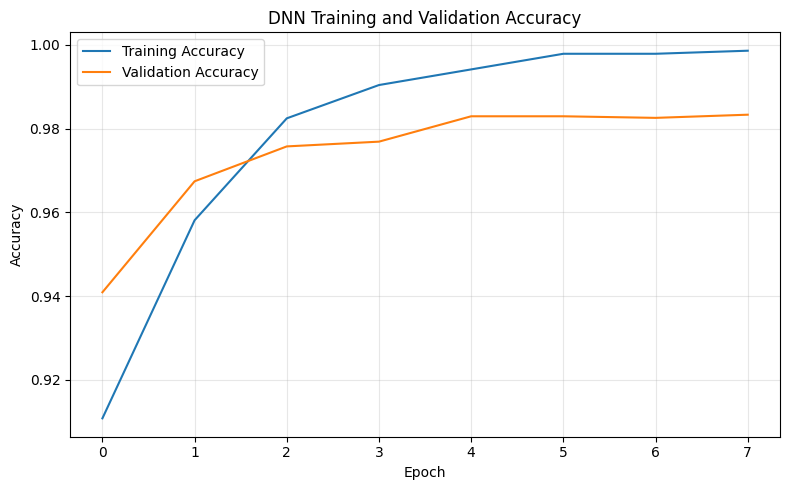

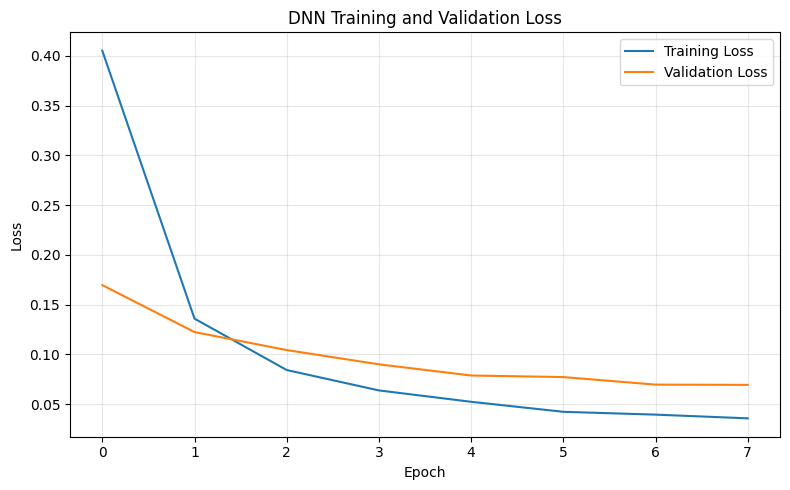

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

ax.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

ax.set_title("DNN Training and Validation Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "dnn_accuracy.png",
    dpi=200
)
plt.show()


fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    history.history["loss"],
    label="Training Loss"
)

ax.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

ax.set_title("DNN Training and Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "dnn_loss.png",
    dpi=200
)
plt.show()

## 3. Validation Evaluation

The trained DNN will be evaluated using the
validation dataset.

Metrics include:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Average Precision

The initial classification threshold is 0.50.

The test set remains reserved for final evaluation.

DNN VALIDATION RESULTS


,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
DNN,0.9769,0.6914,0.9453,0.7987,0.9968,0.9537


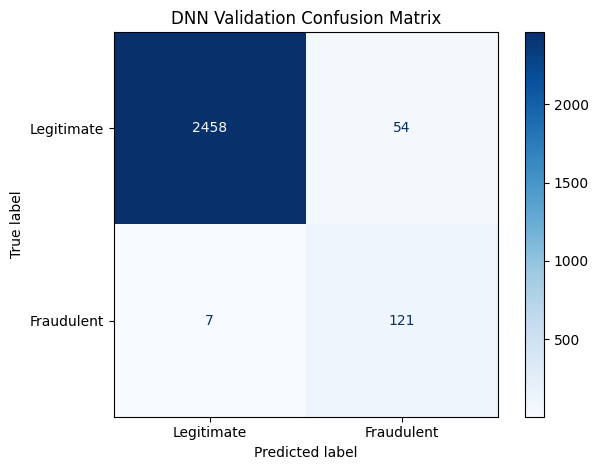

True Negatives: 2458
False Positives: 54
False Negatives: 7
True Positives: 121


In [6]:
validation_scores = model.predict(
    X_val,
    batch_size=256,
    verbose=0
).ravel()

validation_predictions = (
    validation_scores >= 0.50
).astype(int)

metrics = {
    "Accuracy": accuracy_score(
        y_val, validation_predictions
    ),
    "Precision": precision_score(
        y_val, validation_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_val, validation_predictions,
        zero_division=0
    ),
    "F1": f1_score(
        y_val, validation_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_val, validation_scores
    ),
    "Average Precision": average_precision_score(
        y_val, validation_scores
    )
}

dnn_results = pd.DataFrame(
    [metrics],
    index=["DNN"]
)

print("DNN VALIDATION RESULTS")
display(dnn_results.round(4))

dnn_results.to_csv(
    REPORT_DIR / "dnn_validation_metrics.csv"
)

cm = confusion_matrix(
    y_val,
    validation_predictions,
    labels=[0, 1]
)

display_object = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Legitimate",
        "Fraudulent"
    ]
)

display_object.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("DNN Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "dnn_confusion_matrix.png",
    dpi=200
)

plt.show()

print("True Negatives:", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives:", cm[1, 1])

In [7]:
model_path = MODEL_DIR / "jobshield_dnn.keras"

model.save(model_path)

print("Model saved:", model_path)

# Reload model independently
loaded_model = tf.keras.models.load_model(
    model_path,
    compile=False
)

# Compare predictions before and after saving
original_prediction = model.predict(
    X_val[:1],
    verbose=0
)

loaded_prediction = loaded_model.predict(
    X_val[:1],
    verbose=0
)

np.testing.assert_allclose(
    original_prediction,
    loaded_prediction,
    rtol=1e-5,
    atol=1e-5
)

required_files = [
    model_path,
    REPORT_DIR / "dnn_training_history.csv",
    REPORT_DIR / "dnn_validation_metrics.csv",
    FIGURE_DIR / "dnn_accuracy.png",
    FIGURE_DIR / "dnn_loss.png",
    FIGURE_DIR / "dnn_confusion_matrix.png"
]

for path in required_files:
    assert path.exists(), f"Missing file: {path}"
    print("PASS:", path.name)

print("\nDNN saving and verification completed.")

Model saved: d:\the_land_of_the_code\college index\ANN-LAB\FINAL PROJECT\models\jobshield_dnn.keras
PASS: jobshield_dnn.keras
PASS: dnn_training_history.csv
PASS: dnn_validation_metrics.csv
PASS: dnn_accuracy.png
PASS: dnn_loss.png
PASS: dnn_confusion_matrix.png

DNN saving and verification completed.


## 4. DNN Training Conclusion

The Deep Neural Network has been implemented using
TensorFlow/Keras.

### Implementation
- Dense hidden layers with ReLU activation
- Sigmoid output for binary classification
- Binary cross-entropy loss
- Adam optimiser
- Dropout and L2 regularisation
- Class weighting
- Early stopping

### Outputs
- Trained DNN model
- Training and validation history
- Accuracy and loss curves
- Validation evaluation metrics
- Confusion matrix

### Next Phase

05 — Model Evaluation and Comparison

The DNN will be compared against Logistic Regression.

The final untouched test dataset will be evaluated
after selecting the model and decision threshold.